# TurboQuant 7B 확인 실험: 실행 가능한 단일 진입점

목표는 **KV cache를 줄이면서 실제 QA 품질을 유지하는가**, 그리고 **동일 서버에서
처리량·tail latency가 어떻게 변하는가**를 확인하는 것이다. 아래 셀은 설정과 원시
결과를 검증하고 표·그림을 다시 만든다. GPU 실험도 같은 노트북에서 실행할 수 있지만,
실수로 긴 작업을 시작하지 않도록 기본값은 `RUN_GPU=0`이다.

핵심 판정: Qwen2.5-7B-Instruct, LongBench HotpotQA 200문항에서 K8V4만 사전 정의한
F1 비열등성 한계 −0.02를 통과했다. 4bit-NC는 평균 차이가 작아도 CI 하한이 기준을
넘었고, 무보정 FP8 E4M3은 품질이 붕괴했다.

## 먼저 보는 전체 지도

이 실험은 “파일 크기를 줄였나?”가 아니라 아래 연결된 질문을 순서대로 검사한다.

1. **모델은 무엇을 기억하는가?** 생성 중 과거 token의 Key와 Value를 GPU에 보관한다.
2. **무엇을 압축하는가?** 모델 weight가 아니라 요청마다 커지는 **KV cache**다.
3. **압축 후 답이 유지되는가?** 실제 multi-hop QA의 paired F1으로 검사한다.
4. **서비스가 좋아지는가?** 처리량과 TTFT·TPOT·E2E tail latency를 별도로 잰다.
5. **결론은 언제 채택인가?** 품질 gate와 serving/capacity gate를 둘 다 통과해야 한다.

`압축률 → 품질 → serving → 운영 안전성` 중 하나라도 빠지면 제품 결론이 아니다.

## 1. 언어 모델·Attention·KV cache 기초

### 1.1 Autoregressive 생성

언어 모델은 입력 token $x_1,\ldots,x_t$를 읽고 다음 token의 확률
$p(x_{t+1}|x_{\le t})$을 계산한다. 한 token을 출력할 때마다 같은 과거 문맥을
다시 읽는다면 낭비가 크다. Transformer는 각 과거 token에서 만든 Key와 Value를
저장해 재사용한다.

한 attention head의 핵심 계산은

$$
\operatorname{Attention}(Q,K,V)
=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_h}}\right)V
$$

다. Query는 “지금 무엇을 찾는가”, Key는 “과거 token이 어떤 단서인가”, Value는
“선택했을 때 가져올 내용”으로 이해하면 된다. 새 Query는 과거의 모든 Key와
유사도를 비교한 뒤, 그 점수로 Value를 가중합한다.

### 1.2 KV cache가 왜 병목인가?

레이어 수 $L$, token 수 $T$, KV head 수 $H_{kv}$, head dimension $d_h$,
원소당 bit 수 $b$일 때 순수 payload는 대략

$$
B_{KV}=2LTH_{kv}d_h\frac{b}{8}
$$

이다. 앞의 2는 K와 V 두 배열을 뜻한다. 문맥과 동시 요청이 늘면 메모리가 선형으로
증가한다. 실제 사용량에는 scale, norm, page padding, allocator와 workspace도
포함되므로 “4-bit면 정확히 1/4”이라고 단정하면 안 된다.

## 2. 핵심 모델 Qwen2.5-7B-Instruct

이번 기준 모델은 instruction-tuned causal LM인 `Qwen/Qwen2.5-7B-Instruct`다.
실험은 revision `a09a35458c702b33eeacc393d103063234e8bc28`을 고정했다.

| 항목 | 값 | 실험에서 중요한 이유 |
|---|---:|---|
| 전체 parameter | 7.61B | 0.6B pilot보다 실제 QA baseline이 충분히 강함 |
| Transformer layer | 28 | 모든 layer가 KV를 저장하므로 cache 비용에 직접 영향 |
| Query/KV heads | 28 / 4 | Grouped Query Attention으로 KV head를 이미 줄인 모델 |
| 구성 | RoPE, SwiGLU, RMSNorm, QKV bias | 모델 구조를 바꾸지 않고 KV dtype만 비교 |
| 공개 context 지원 | 최대 131,072 | 본 실험은 공정한 GPU 예산을 위해 16,384 이하 사용 |

GQA는 여러 Query head가 적은 KV head를 공유한다. 즉 Qwen 자체가 이미 KV 메모리를
아끼는데, 그 남은 KV를 추가로 저비트화했을 때 품질이 유지되는지가 더 엄격한 질문이다.

## 3. 양자화 기초와 네 baseline

양자화는 실수 $x$를 제한된 code $q$로 바꾸고, 필요할 때 근사값 $\hat{x}$로
복원하는 과정이다. uniform quantization의 단순 형태는

$$q=\operatorname{clip}(\operatorname{round}(x/s),q_{min},q_{max}),
\qquad \hat{x}=sq$$

이며 $s$는 scale이다. bit가 적으면 저장량은 줄지만 rounding·clipping 오차가 커진다.

| 방법 | 의미 | 역할 |
|---|---|---|
| `auto` | BF16 KV | 품질·성능 기준선 |
| `fp8_e4m3` | vLLM 기본 FP8 E4M3 KV | 일반 저정밀 기준선; 이번에는 scale 미보정 |
| `turboquant_k8v4` | Key 8-bit, Value 4-bit | 품질 보존을 우선한 TurboQuant 후보 |
| `turboquant_4bit_nc` | Key/Value 4-bit, correction 없음 | 더 공격적인 capacity 후보 |

중요한 구분은 **weight quantization**과 **KV-cache quantization**이다. 전자는 모델
parameter를 줄이고, 후자는 요청 길이·동시성에 따라 증가하는 runtime state를 줄인다.
이번 결론은 KV cache에만 해당한다.

## 4. TurboQuant를 직관적으로 이해하기

### 4.1 왜 회전하는가?

원본 벡터의 몇 좌표에 outlier가 몰리면 좁은 bit 범위가 outlier에 소비된다.
TurboQuant-MSE는 벡터를 norm으로 정규화한 뒤 무작위 직교 회전 $R$을 적용한다.

$$u=x/\|x\|_2,\qquad z=Ru$$

고차원에서 회전된 좌표는 집중된 분포를 이루므로 좌표별 scalar quantizer를
효율적으로 설계할 수 있다. 복원은 대략

$$\hat{x}=\|x\|_2R^\top q(z)$$

형태다. 정보가 사라지지 않게 만드는 마법이 아니라, 같은 bit 수에서 오차가 특정
좌표에 몰리는 것을 줄이는 전처리다.

### 4.2 MSE와 attention 품질은 같은가?

아니다. 작은 평균제곱오차가 $QK^\top$의 순위와 softmax 확률을 반드시 보존하지는
않는다. 논문은 inner-product bias를 다루는 residual/QJL 방식도 제안하지만,
production kernel의 실제 preset과 논문 알고리즘의 모든 변형을 동일시하면 안 된다.
따라서 본 실험은 NumPy 모사가 아니라 vLLM 0.26.0 본류의 TurboQuant backend로
최종 QA와 serving을 직접 측정했다. 이것은 **논문 저자의 standalone 공식 레포가
아니며**, vLLM 프로젝트가 통합한 production 구현이다. 이 구현은 논문의 QJL을
의도적으로 생략하므로 “논문 전체의 그대로인 공식 구현”이라고 부르지 않는다.

### 4.3 그래서 어떤 저장소를 사용했나?

이 PoC의 실행 계보는 다음처럼 분리한다.

| 층 | 사용 여부 | 역할과 한계 |
|---|---|---|
| TurboQuant 논문 | 이론 기준 | 회전·MSE quantizer·residual QJL과 논문 benchmark를 정의 |
| 논문 저자 standalone repo | 없음 | 조사 시점에 공개된 저자 공식 저장소를 확인하지 못함 |
| `vllm-project/vllm` 0.26.0 | **주 실행 구현** | `TURBOQUANT` attention backend와 packed CUDA kernel을 실제 호출 |
| 이 저장소의 NumPy teaching reference | 단위검증만 | 회전·codebook 직관용; 성능/공식 재현 근거로 사용하지 않음 |
| 제3자 TurboQuant 포트 | 미사용 | 저자 공식 구현이 아니며 결과 비교의 동등성을 보장하기 어려움 |

즉 “공식 레포로 재현했다”가 아니라 **공개 논문을 기준으로, vLLM 프로젝트의
mainline 구현을 실서버에서 검증했다**가 정확한 표현이다. 코드의 실제 preset도
논문 전체와 다르다. `turboquant_k8v4`는 Key FP8 + Value 4-bit이고,
`turboquant_4bit_nc`는 회전/Lloyd–Max 계열의 4-bit K/V와 norm correction을
사용하지만 QJL은 생략한다.

### 4.4 전신·비교 방법은 무엇인가?

TurboQuant를 한 방법만의 승패로 보면 안 된다. 비교축은 “같은 bit budget에서
무엇으로 오차와 메모리를 줄이는가”다.

| 방법군 | 핵심 아이디어 | 공정 비교에서 볼 것 |
|---|---|---|
| BF16/FP16 KV | 압축하지 않음 | 품질 기준, bytes/token 기준 |
| FP8 / uniform INT4 | 단순 저정밀 저장 | scale 보정 유무, kernel 비용 |
| KIVI | K/V별 비대칭 per-channel/per-token 양자화 | residual window 포함 실제 bit/token |
| KVQuant | calibration/outlier-aware KV 양자화 | calibration 비용과 동일 품질 |
| QJL | 1-bit 투영으로 inner product 추정 | unbiasedness와 kernel overhead |
| PolarQuant | 회전 후 분포 구조를 이용한 quantization | metadata 포함 rate–distortion |
| TurboQuant | 회전·MSE quantization·QJL 계열 결합 | 품질, bit/channel, latency를 함께 |
| SnapKV/PyramidKV | 중요한 token만 남기는 pruning | 같은 cache budget의 품질·회수율 |

현재 완료된 실험은 BF16, 무보정 FP8, vLLM K8V4, vLLM 4bit-NC 비교다.
KIVI·KVQuant·PolarQuant·QJL full algorithm은 **다음 공정 benchmark baseline**이지,
이미 실행했다고 주장하지 않는다. 서로 kernel/runtime이 달라 peak allocated memory만
비교하지 말고 실제 payload bit/token, 최대 동시 sequence, F1, TTFT/TPOT를 함께 고정한다.

## 5. 데이터와 통계: 왜 HotpotQA 200문항인가?

HotpotQA는 여러 Wikipedia 문서의 단서를 연결해야 답할 수 있는 multi-hop QA다.
LongBench가 제공하는 입력·prompt·평가 규약을 사용했고, 데이터 파일 SHA-256은
`a0005ab2...92ef6f`로 고정했다.

### 5.1 normalized token-F1

예측과 정답을 소문자화하고 관사·구두점·불필요한 공백을 정규화한 뒤 token overlap의
precision과 recall 조화평균을 계산한다.

$$F1=\frac{2PR}{P+R}$$

완전일치보다 표현 차이에 덜 민감하지만, 정답 의미 전체를 평가하는 생성형 judge는
아니다.

### 5.2 paired bootstrap과 비열등성

네 방법은 **동일한 200문항**을 푼다. 각 질문에서
$d_i=F1_{method,i}-F1_{BF16,i}$를 만든 뒤 질문을 복원추출해 평균 차이의 95% CI를
계산한다. 독립 표본처럼 비교하는 것보다 질문 난이도를 통제할 수 있다.

- baseline floor: BF16 평균 F1 ≥ 0.20
- non-inferiority margin: $\Delta=-0.02$
- 통과: 평균 차이 CI의 하한 ≥ −0.02

평균 차이가 작아 보여도 CI 하한이 margin 아래면 “성능 유지”라고 말하지 않는다.

## 6. Serving 지표를 읽는 법

| 지표 | 질문 | 낮을수록/높을수록 |
|---|---|---|
| requests/s | 초당 몇 요청을 끝내는가? | 높을수록 좋음 |
| TTFT | 요청 후 첫 token까지 얼마나 기다리는가? | 낮을수록 좋음 |
| TPOT | 첫 token 뒤 token 사이 간격은? | 낮을수록 좋음 |
| E2E | 요청 전체 완료까지 걸린 시간은? | 낮을수록 좋음 |
| P99 | 가장 느린 1% 경계는? | 낮을수록 좋음 |

short는 입력/출력 256/64, 동시성 64, 1,000요청이다. long은 4096/128,
동시성 16, 256요청이다. 각 방법을 새 서버 process에서 3회 반복하고 순서를
무작위화했다. 단, 반복 3회 CI는 정밀한 모집단 추론보다 실행 변동을 확인하는
탐색 통계다.

In [1]:
from pathlib import Path
import os, subprocess
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent
RUN_GPU = os.getenv("RUN_GPU", "0") == "1"
labels = {
    "auto": "BF16",
    "fp8_e4m3": "FP8 (uncalibrated)",
    "turboquant_k8v4": "TurboQuant K8V4",
    "turboquant_4bit_nc": "TurboQuant 4-bit NC",
}
print("repository:", ROOT)
print("GPU stages enabled:", RUN_GPU)

repository: quantumai-tech-poc
GPU stages enabled: False


## 7. 잠긴 실험 계약

- 모델: `Qwen/Qwen2.5-7B-Instruct`, revision 고정
- 데이터: LongBench HotpotQA 파일 SHA-256 고정, seed 고정 200문항
- 공식 LongBench prompt, Qwen chat template, normalized token-F1
- paired bootstrap 10,000회, 95% CI
- 통과 조건: BF16 F1 ≥ 0.20이고 delta CI 하한 ≥ −0.02
- serving: 방법 순서 무작위화, 독립 서버 재시작 3회, workload별 warm-up 64건

FP8은 vLLM 기본 E4M3 scale을 사용한 **무보정 조건**이다. 이 결과를 “FP8 일반의
실패”로 확장하면 안 된다.

In [2]:
quality = pd.read_csv(ROOT / "results/vllm_turboquant_quality_7b_summary.csv")
online = pd.read_csv(ROOT / "results/vllm_turboquant_online_7b_summary.csv")
monitor = pd.read_csv(ROOT / "results/gpu3_confirmatory_summary.csv")
compat = pd.read_csv(ROOT / "results/model_compatibility_summary.csv")
quality["method"] = quality["kv_dtype"].map(labels)
online["method"] = online["kv_dtype"].map(labels)
assert quality["config_hash"].nunique() == 1
assert online["config_hash"].nunique() == 1
assert set(quality["kv_dtype"]) == set(labels)
assert set(online["kv_dtype"]) == set(labels)
quality

,kv_dtype,n,mean_f1,delta_vs_bf16,ci95_low,ci95_high,baseline_floor_pass,non_inferior,truncated_count,length_finished_count,elapsed_seconds,config_hash,method
0,auto,200,0.566181,0.000000,0.000000,0.000000,True,True,66,23,186.830188,a5eec13d025f7665100342821cc2e450aef22ffe370c8c...,BF16
1,fp8_e4m3,200,0.032336,-0.533844,-0.594996,-0.470803,True,False,66,166,180.238665,a5eec13d025f7665100342821cc2e450aef22ffe370c8c...,FP8 (uncalibrated)
2,turboquant_k8v4,200,0.565971,-0.000210,-0.019060,0.020192,True,True,66,21,184.190197,a5eec13d025f7665100342821cc2e450aef22ffe370c8c...,TurboQuant K8V4
3,turboquant_4bit_nc,200,0.563653,-0.002528,-0.024712,0.020061,True,False,66,22,185.315754,a5eec13d025f7665100342821cc2e450aef22ffe370c8c...,TurboQuant 4-bit NC


## 8. 선택 실행: GPU 단계

서버에서 `RUN_GPU=1`로 실행할 때만 아래 두 명령이 동작한다. 품질은 네 방법의 동일
문항을 만들고, serving은 4방법 × 3재시작 × 2 workload를 수행한다. 기존 결과를
덮어쓰지 않도록 실제 재실행 전에는 별도 결과 디렉터리로 바꾸는 것이 안전하다.

In [3]:
if RUN_GPU:
    env = {**os.environ, "PYTHONPATH": str(ROOT / "src")}
    for dtype in labels:
        subprocess.run([
            "python", str(ROOT / "scripts/run_vllm_quality.py"),
            "--config", str(ROOT / "quality_confirmatory_7b.toml"),
            "--data", str(ROOT / "data/longbench/data/hotpotqa.jsonl"),
            "--kv-dtype", dtype,
            "--output", str(ROOT / f"results/vllm-quality-7b/{dtype}.json"),
        ], check=True, env=env)
    subprocess.run([
        "python", str(ROOT / "scripts/run_vllm_online.py"),
        "--config", str(ROOT / "serving_confirmatory.toml"),
        "--result-dir", str(ROOT / "results/vllm-online-7b"),
        "--gpu", "3",
    ], check=True, env=env)
else:
    print("Skipped safely. Set RUN_GPU=1 only on the reserved server GPU.")

Skipped safely. Set RUN_GPU=1 only on the reserved server GPU.


## 9. 품질: 평균만 보지 말고 paired CI로 판정

같은 질문에서 BF16과 각 방법의 F1 차이를 계산했다. K8V4의 하한은 −0.01906으로
−0.02를 간신히 통과한다. 4bit-NC 하한은 −0.02471이라 통과하지 못한다.

In [4]:
cols = ["method", "n", "mean_f1", "delta_vs_bf16", "ci95_low",
        "ci95_high", "baseline_floor_pass", "non_inferior",
        "truncated_count", "length_finished_count"]
quality[cols]

,method,n,mean_f1,delta_vs_bf16,ci95_low,ci95_high,baseline_floor_pass,non_inferior,truncated_count,length_finished_count
0,BF16,200,0.566181,0.000000,0.000000,0.000000,True,True,66,23
1,FP8 (uncalibrated),200,0.032336,-0.533844,-0.594996,-0.470803,True,False,66,166
2,TurboQuant K8V4,200,0.565971,-0.000210,-0.019060,0.020192,True,True,66,21
3,TurboQuant 4-bit NC,200,0.563653,-0.002528,-0.024712,0.020061,True,False,66,22


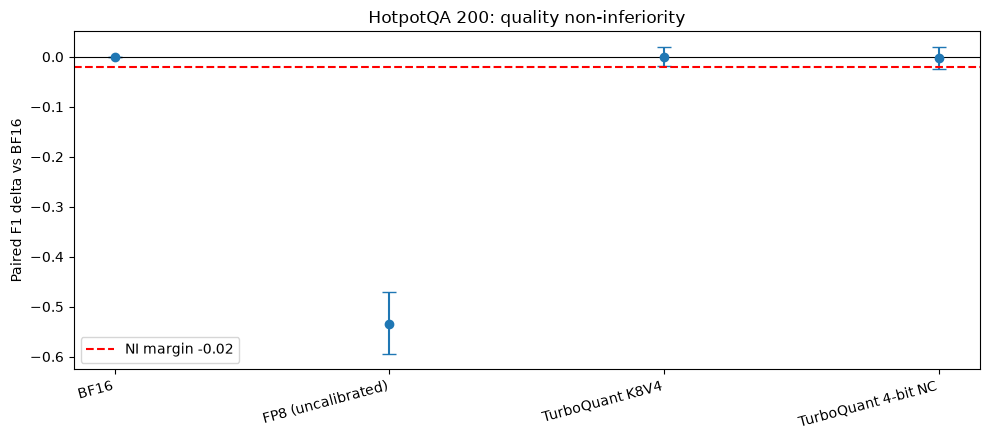

In [5]:
q = quality.set_index("method").loc[list(labels.values())]
y = q["delta_vs_bf16"]
plt.figure(figsize=(10, 4.5))
plt.errorbar(q.index, y, yerr=[y-q["ci95_low"], q["ci95_high"]-y],
             fmt="o", capsize=5)
plt.axhline(-0.02, color="red", ls="--", label="NI margin -0.02")
plt.axhline(0, color="black", lw=.8)
plt.ylabel("Paired F1 delta vs BF16")
plt.title("HotpotQA 200: quality non-inferiority")
plt.xticks(rotation=15, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig(ROOT / "figures/turboquant_7b_quality_ci.png", dpi=180)
plt.show()

## 10. Serving: 재시작 평균과 범위

각 막대는 독립 서버 재시작 3회의 평균이고 오차막대는 관측 최소–최대다. 표의
bootstrap CI도 n=3이므로 정밀한 불확실성 추정이 아니라 실행 간 변동 확인용이다.
`jit_contaminated_runs`가 0인지 함께 확인한다. TurboQuant short는 측정과 동일한
1,000-request 선행 warm-up을 사용하고, 측정 중 JIT가 검출되면 같은 서버에서 1회
재측정했다. 최종 24개 측정은 모든 방법과 workload에서 JIT 오염 0/3이었다.

In [6]:
online[["workload", "method", "restarts", "jit_contaminated_runs",
        "request_throughput_mean", "request_throughput_min",
        "request_throughput_max", "p99_e2el_ms_mean"]]

,workload,method,restarts,jit_contaminated_runs,request_throughput_mean,request_throughput_min,request_throughput_max,p99_e2el_ms_mean
0,long,BF16,3,0,3.542237,3.541001,3.544506,6011.031744
1,long,FP8 (uncalibrated),3,0,3.767991,3.764109,3.771557,5484.098104
2,long,TurboQuant 4-bit NC,3,0,2.995846,2.994649,2.998139,6939.257357
3,long,TurboQuant K8V4,3,0,3.027994,3.025644,3.031091,7249.262933
4,short,BF16,3,0,37.745007,37.646310,37.832935,1893.248249
5,short,FP8 (uncalibrated),3,0,38.071783,38.029264,38.116909,1786.498479
6,short,TurboQuant 4-bit NC,3,0,47.572015,47.358161,47.889113,1394.599287
7,short,TurboQuant K8V4,3,0,50.609928,50.519504,50.753156,1333.598608


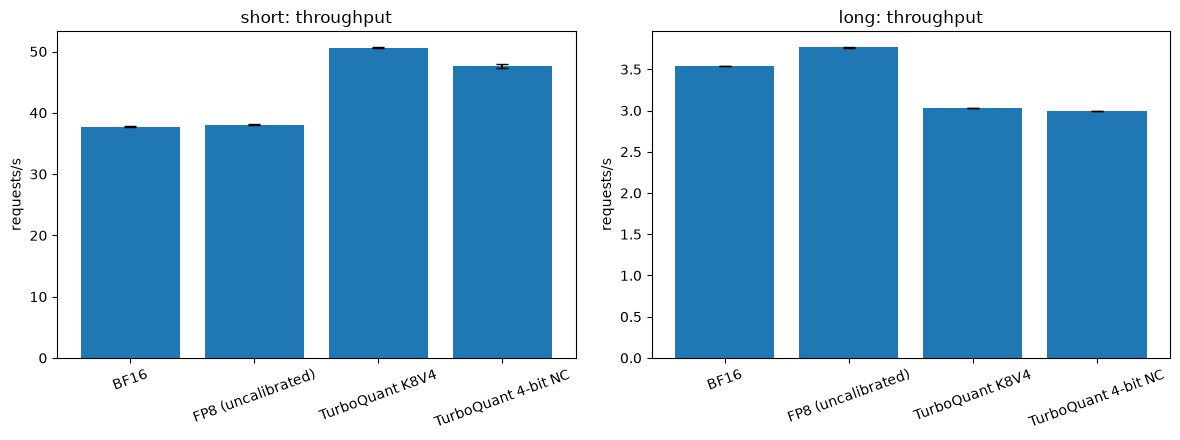

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, workload in zip(axes, ["short", "long"]):
    frame = online[online.workload == workload].set_index("method").loc[list(labels.values())]
    mean = frame["request_throughput_mean"]
    ax.bar(mean.index, mean)
    ax.errorbar(mean.index, mean,
                yerr=[mean-frame["request_throughput_min"],
                      frame["request_throughput_max"]-mean],
                fmt="none", color="black", capsize=4)
    ax.set(title=f"{workload}: throughput", ylabel="requests/s")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(ROOT / "figures/turboquant_7b_serving_restarts.png", dpi=180)
plt.show()

## 11. 모델군·크기 호환성 smoke

본 품질 실험의 주 모델은 **Qwen2.5-7B-Instruct**다. 그 전에 Qwen3-0.6B로
kernel/capacity를 선별했고, 후속 호환성 smoke에서 아래 1B급 세 계열을 추가했다.

| 계열 | 모델 | parameter | 목적 |
|---|---|---:|---|
| Llama | Llama-3.2-1B-Instruct | 1.236B | 일반 decoder 계열 호환성 |
| Gemma | Gemma-3-1B-it | 1.000B | sliding-window 구조 호환성 |
| Qwen | Qwen2.5-1.5B-Instruct | 1.544B | 주 모델과 같은 계열의 작은 확인점 |

각 모델에 BF16과 K8V4를 적용하고 chat template 뒤 산술 1개, 수도 1개,
약 228–233 token distractor needle 1개를 greedy 생성했다. 이는 실제 데이터셋
품질 평가가 아니라 **로드·생성·간단 parity** smoke다.

In [8]:
compat[["family", "model", "parameters", "kv_dtype", "status", "kv_tokens",
        "arithmetic_pass", "capital_pass", "needle_pass", "failure_reason"]]

,family,model,parameters,kv_dtype,status,kv_tokens,arithmetic_pass,capital_pass,needle_pass,failure_reason
0,Llama,meta-llama/Llama-3.2-1B-Instruct,1235814400,auto,executed,2065888.0,True,True,False,NaN
1,Llama,meta-llama/Llama-3.2-1B-Instruct,1235814400,turboquant_k8v4,executed,3804800.0,True,False,False,NaN
2,Gemma,google/gemma-3-1b-it,999885952,auto,executed,2371479.0,True,True,False,NaN
3,Gemma,google/gemma-3-1b-it,999885952,turboquant_k8v4,unsupported,NaN,False,False,False,No valid attention backend found for cuda with...
4,Qwen,Qwen/Qwen2.5-1.5B-Instruct,1543714304,auto,executed,2333696.0,True,True,False,NaN
5,Qwen,Qwen/Qwen2.5-1.5B-Instruct,1543714304,turboquant_k8v4,executed,4954976.0,True,True,False,NaN


Llama와 Qwen은 K8V4 backend가 실행됐다. 같은 0.70 GPU budget에서 allocator 기준
KV token은 Llama 1.84×, Qwen 2.12× 늘었다. Gemma 3 K8V4는 sliding-window
attention을 vLLM 0.26.0 TurboQuant backend가 지원하지 않아 초기화 단계에서 실패했다.

Qwen 1.5B는 BF16/K8V4 모두 산술·수도 응답이 같았다. Llama K8V4는 BF16이 맞힌
수도 응답을 놓쳤고, 세 1B급 모델 모두 distractor needle을 회수하지 못했다.
따라서 이 smoke는 범용 품질 유지 증거가 아니며, 7B HotpotQA 결과와 분리한다.

### 11.1 Sliding-window attention은 무엇인가?

일반 causal attention은 새 token이 과거 **전체** $T$개 token을 볼 수 있다.
Sliding-window attention은 각 layer가 최근 $W$개만 보게 해 계산과 KV 보관을
제한한다.

$$
\text{full: }j\le i,\qquad
\text{window: }\max(0,i-W+1)\le j\le i
$$

예를 들어 현재 위치가 8이고 window가 4라면 full은 token 1–8을 보지만 window는
5–8만 직접 본다. 여러 layer를 거치며 정보가 간접 전파될 수 있고, 일부 모델은
full-attention layer와 window layer를 섞는다. 따라서 “옛 token을 무조건 잊는다”는
뜻은 아니지만 backend는 layer마다 다른 cache 범위·offset·mask를 정확히 처리해야 한다.

Gemma 3의 실패는 모델 품질 실패가 아니다. vLLM 0.26.0의 TurboQuant backend
capability check가 sliding-window를 지원하지 않아 **생성 전에 거부한 구조 호환성
실패**다. BF16 경로는 실행되므로 모델 자체나 checkpoint 손상으로 해석하지 않는다.

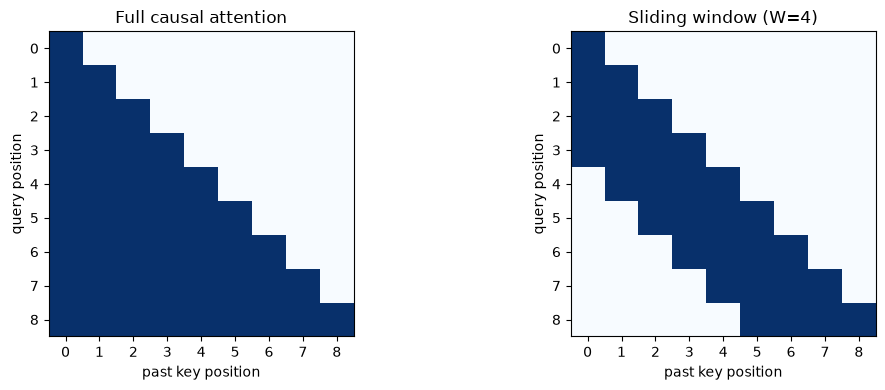

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
n, w = 9, 4
full = [[1 if j <= i else 0 for j in range(n)] for i in range(n)]
window = [[1 if max(0, i-w+1) <= j <= i else 0 for j in range(n)] for i in range(n)]
for ax, mask, title in zip(
    axes, [full, window], ["Full causal attention", f"Sliding window (W={w})"]
):
    ax.imshow(mask, cmap="Blues", vmin=0, vmax=1)
    ax.set(title=title, xlabel="past key position", ylabel="query position")
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
plt.tight_layout()
plt.savefig(ROOT / "figures/sliding_window_attention.png", dpi=180)
plt.show()

위 그림에서 파란 칸은 Query가 접근 가능한 Key다. 왼쪽 삼각형은 과거 전체를,
오른쪽 띠 모양은 최근 window만 본다. 이 구조는 이론적으로 KV 비용을
$O(T)$에서 layer당 $O(W)$로 제한할 수 있지만, 현재 사용한 TurboQuant kernel은
이 mask/cache contract를 구현하지 않아 Gemma 3에 연결할 수 없다.

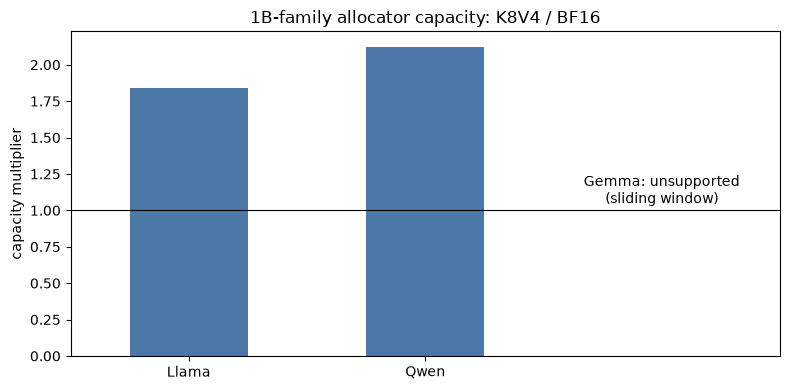

In [10]:
pivot = compat.pivot(index="family", columns="kv_dtype", values="kv_tokens")
ratio = (pivot["turboquant_k8v4"] / pivot["auto"]).dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ratio.plot.bar(ax=ax, color="#4C78A8")
ax.axhline(1, color="black", lw=.8)
ax.set(title="1B-family allocator capacity: K8V4 / BF16",
       ylabel="capacity multiplier", xlabel="")
ax.set_xlim(-.5, 2.5)
ax.text(2, 1.05, "Gemma: unsupported\n(sliding window)", ha="center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(ROOT / "figures/turboquant_model_compatibility.png", dpi=180)
plt.show()

## 12. GPU 안전성

모니터는 GPU3만 5초 간격으로 기록했다. 아래 표는 완전한 GPU3 행만 사용한
최소·평균·최대값이다. 다른 사용자의 GPU는 실험 대상에서 제외했다.

In [11]:
monitor.T

,0
gpu,3.000000
samples,919.000000
memory_used_mib_min,2.000000
memory_used_mib_mean,55709.468988
memory_used_mib_max,80303.000000
utilization_pct_min,0.000000
utilization_pct_mean,49.952122
utilization_pct_max,100.000000
temperature_c_min,28.000000
temperature_c_mean,48.438520


## 13. 의사결정

1. **후속 최우선 후보: K8V4.** 실제 QA 비열등성 gate를 통과한 유일한 압축 방법이다.
2. **4bit-NC: 연구 후보, 제품 기본값 아님.** 평균 손실은 작지만 현재 CI로는 gate 실패다.
3. **무보정 FP8: 제외.** 빠르더라도 품질 gate를 크게 실패했다. calibrated scale은 별도 실험이다.
4. **TQ short는 JIT-clean에서 이득.** K8V4 50.61, 4bit-NC 47.57 req/s로 BF16 37.75보다 높았다.
5. **Gemma 3는 현재 제외.** vLLM 0.26.0 TQ backend가 sliding-window attention을 지원하지 않는다.
6. **아직 미증명:** 실제 production trace, 고동시성 capacity/OOM crossover, 다른 모델·태스크
   일반화. 이 항목은 이번 실험으로 증명했다고 쓰지 않는다.

## 근거 자료

- [TurboQuant 논문](https://arxiv.org/abs/2504.19874)
- [vLLM 공식 TurboQuant attention backend](https://docs.vllm.ai/en/stable/api/vllm/v1/attention/backends/turboquant_attn/)
- [Qwen2.5-7B-Instruct 공식 model card](https://huggingface.co/Qwen/Qwen2.5-7B-Instruct)
- [LongBench 공식 저장소](https://github.com/THUDM/LongBench)
- [HotpotQA 공식 홈페이지](https://hotpotqa.github.io/)

위 외부 자료의 논문 주장과 이 저장소의 측정치는 구분한다. 표에 표시된 F1·CI·처리량·
GPU 수치는 이 PoC의 고정 설정에서 직접 얻은 값이다.